# 01 - Audit Data Harga dan Klasifikasi Gap

Notebook ini mengecek kualitas data harga XAUUSD H1 (duplikasi waktu, urutan, nilai kosong, dan konsistensi OHLC) serta mengklasifikasikan setiap *gap* (celah antarbar) menjadi tiga jenis:

1. **penutupan_terjadwal** (jeda harian rutin dan akhir pekan) -> wajar, indikator berlanjut.
2. **penutupan_sesuai_bursa** (hari libur resmi CME) -> wajar, indikator berlanjut.
3. **tak_terjelaskan** -> dianggap data terputus, sehingga indikator direset sebagai **segmen** baru.

In [1]:
import os
import tomllib
import pandas as pd
import matplotlib.pyplot as plt

PATH_HARGA = "../data/research/windows-feasibility-2026-08-09/metaquotes-demo/market.csv"
PATH_JADWAL = "../configs/phase4-market-gaps.toml"
OUT_DIR = "../data/interim/phase4-p0"
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Baca Data Harga

Satu baris mewakili satu bar H1, dengan kolom `time` sebagai waktu pembukaan bar (UTC).

In [2]:
harga = pd.read_csv(PATH_HARGA)
harga["time"] = pd.to_datetime(harga["time"], utc=True)
harga = harga[["time", "open", "high", "low", "close"]]

print("Jumlah bar :", len(harga))
print("Rentang    :", harga["time"].min(), "s.d.", harga["time"].max())
harga.head()

Jumlah bar : 38799
Rentang    : 2020-01-02 06:00:00+00:00 s.d. 2026-07-31 22:00:00+00:00


,time,open,high,low,close
0,2020-01-02 06:00:00+00:00,1520.26,1520.36,1519.39,1519.39
1,2020-01-02 07:00:00+00:00,1519.37,1520.36,1518.95,1520.19
2,2020-01-02 08:00:00+00:00,1520.20,1520.91,1519.30,1520.87
3,2020-01-02 09:00:00+00:00,1520.94,1521.37,1519.03,1519.11
4,2020-01-02 10:00:00+00:00,1519.11,1520.93,1518.38,1520.75


## 2. Cek Kualitas Data Dasar

Data tidak diinterpolasi ataupun diisi nilai buatan. Di sini kita cek apakah ada duplikasi waktu, urutan terbalik, nilai kosong, harga <= 0, atau OHLC yang tidak konsisten.

In [3]:
ohlc = ["open", "high", "low", "close"]

print("Duplikasi waktu          :", harga["time"].duplicated().sum())
print("Urutan waktu naik        :", harga["time"].is_monotonic_increasing)
print("Waktu tepat di awal jam  :", (harga["time"].dt.floor("h") == harga["time"]).all())
print("Jumlah nilai kosong OHLC :", harga[ohlc].isna().sum().sum())
print("Harga <= 0               :", (harga[ohlc] <= 0).sum().sum())
print("high < max(open, close)  :", (harga["high"] < harga[["open", "close"]].max(axis=1)).sum())
print("low  > min(open, close)  :", (harga["low"] > harga[["open", "close"]].min(axis=1)).sum())

Duplikasi waktu          : 0
Urutan waktu naik        : True
Waktu tepat di awal jam  : True
Jumlah nilai kosong OHLC : 0
Harga <= 0               : 0
high < max(open, close)  : 0
low  > min(open, close)  : 0


## 3. Deteksi Gap

Untuk data H1, jarak normal antarbar adalah 1 jam. Jika selisih waktu antarbar lebih dari 1 jam, berarti terdapat *gap*.

In [4]:
jarak = harga["time"].diff()
posisi_gap = harga.index[jarak > pd.Timedelta(hours=1)]

print("Total gap ditemukan:", len(posisi_gap))
lama_gap = jarak.loc[posisi_gap] / pd.Timedelta(hours=1)
lama_gap.value_counts().head(10).to_frame("jumlah_gap")

Total gap ditemukan: 1705


,jumlah_gap
time,
2.0,1231
50.0,279
3.0,84
4.0,29
51.0,28
6.0,13
49.0,11
74.0,10
53.0,7


## 4. Baca Jadwal Perdagangan & Hari Libur CME

Jadwal perdagangan MetaQuotes-Demo dibagi ke beberapa rezim sesi (mengikuti perubahan *daylight saving time* AS/Eropa) ditambah daftar pengecualian hari libur resmi CME.

In [5]:
with open(PATH_JADWAL, "rb") as f:
    jadwal = tomllib.load(f)["sources"]["metaquotes-demo"]

rezim = pd.DataFrame(jadwal["session_regimes"])[["start", "end", "scheduled_weekdays", "scheduled_hours_utc"]]
rezim["start"] = pd.to_datetime(rezim["start"], utc=True)
rezim["end"] = pd.to_datetime(rezim["end"], utc=True)

pengecualian = pd.DataFrame(jadwal["exceptions"])
pengecualian["start"] = pd.to_datetime(pengecualian["start"], utc=True)
pengecualian["end"] = pd.to_datetime(pengecualian["end"], utc=True)

print("Jumlah rezim sesi   :", len(rezim))
print("Jumlah hari libur   :", len(pengecualian))
pengecualian[["event", "start", "end", "classification"]].head()

Jumlah rezim sesi   : 27
Jumlah hari libur   : 69


,event,start,end,classification
0,Martin Luther King Jr. Day,2020-01-20 20:00:00+00:00,2020-01-21 00:00:00+00:00,exchange_aligned_observed_closure
1,Presidents Day,2020-02-17 20:00:00+00:00,2020-02-18 00:00:00+00:00,exchange_aligned_observed_closure
2,Good Friday,2020-04-10 01:00:00+00:00,2020-04-11 00:00:00+00:00,exchange_aligned_observed_closure
3,Memorial Day,2020-05-25 20:00:00+00:00,2020-05-26 00:00:00+00:00,exchange_aligned_observed_closure
4,Observed Independence Day,2020-07-03 20:00:00+00:00,2020-07-04 00:00:00+00:00,exchange_aligned_observed_closure


## 5. Klasifikasi Setiap Gap

Untuk tiap gap, kita ambil daftar jam yang hilang di antara bar sebelum dan sesudah gap:
- Jika semua jam yang hilang memang jam tutup -> `penutupan_terjadwal`
- Jika jam yang seharusnya buka tercakup oleh libur CME -> `penutupan_sesuai_bursa`
- Selain itu -> `tak_terjelaskan`

In [6]:
def dijadwalkan_buka(ts):
    cocok = rezim[(rezim["start"] <= ts) & (ts < rezim["end"])]
    baris = cocok.iloc[0]
    return (ts.dayofweek in baris["scheduled_weekdays"]) and (ts.hour in baris["scheduled_hours_utc"])

def klasifikasi_gap(sebelum, sesudah):
    jam_hilang = pd.date_range(sebelum + pd.Timedelta(hours=1), sesudah, freq="h", inclusive="left")
    jam_terjadwal = [t for t in jam_hilang if dijadwalkan_buka(t)]

    if len(jam_terjadwal) == 0:
        return "penutupan_terjadwal", None

    for _, e in pengecualian.iterrows():
        if all(e["start"] <= t < e["end"] for t in jam_terjadwal):
            jenis = "penutupan_sesuai_bursa" if e["normal_market_closure"] else "tak_terjelaskan"
            return jenis, e["event"]

    return "tak_terjelaskan", None

gap = pd.DataFrame({
    "bar_sebelum": harga["time"].iloc[posisi_gap - 1].reset_index(drop=True),
    "bar_sesudah": harga["time"].iloc[posisi_gap].reset_index(drop=True),
    "posisi": posisi_gap,
})
gap["lama_jam"] = (gap["bar_sesudah"] - gap["bar_sebelum"]) / pd.Timedelta(hours=1)

hasil_kelas = [klasifikasi_gap(a, b) for a, b in zip(gap["bar_sebelum"], gap["bar_sesudah"])]
gap["kelas"] = [x[0] for x in hasil_kelas]
gap["acara"] = [x[1] for x in hasil_kelas]

gap["kelas"].value_counts().to_frame("jumlah_gap")

,jumlah_gap
kelas,
penutupan_terjadwal,1627
penutupan_sesuai_bursa,69
tak_terjelaskan,9


In [7]:
# Tampilkan semua gap yang tak terjelaskan
tak_jelas = gap[gap["kelas"] == "tak_terjelaskan"].reset_index(drop=True)
tak_jelas[["bar_sebelum", "bar_sesudah", "lama_jam"]]

,bar_sebelum,bar_sesudah,lama_jam
0,2021-06-15 13:00:00+00:00,2021-06-15 15:00:00+00:00,2.0
1,2021-06-18 16:00:00+00:00,2021-06-18 18:00:00+00:00,2.0
2,2021-09-24 18:00:00+00:00,2021-09-24 21:00:00+00:00,3.0
3,2025-01-07 04:00:00+00:00,2025-01-07 07:00:00+00:00,3.0
4,2025-07-03 03:00:00+00:00,2025-07-03 12:00:00+00:00,9.0
5,2025-07-04 04:00:00+00:00,2025-07-04 10:00:00+00:00,6.0
6,2025-10-23 20:00:00+00:00,2025-10-23 22:00:00+00:00,2.0
7,2026-02-26 21:00:00+00:00,2026-02-27 03:00:00+00:00,6.0
8,2026-03-11 22:00:00+00:00,2026-03-12 00:00:00+00:00,2.0


## 6. Bentuk Penanda Gap dan Segmen

- `setelah_gap`: bernilai `True` pada bar pertama setelah gap **jenis apa pun** (dipakai di notebook 02 agar label target tidak melompati gap).
- `segment_id`: bertambah 1 setiap kali ada gap **tak terjelaskan** (dipakai di notebook 03 untuk mereset indikator teknikal).

In [8]:
harga["setelah_gap"] = False
harga.loc[gap["posisi"], "setelah_gap"] = True

harga["reset"] = False
harga.loc[tak_jelas["posisi"], "reset"] = True
harga["segment_id"] = harga["reset"].cumsum()

segmen = harga.groupby("segment_id")["time"].agg(mulai="min", akhir="max", jumlah_bar="count")
print("Total segmen:", len(segmen))
segmen

Total segmen: 10


,mulai,akhir,jumlah_bar
segment_id,,,
0,2020-01-02 06:00:00+00:00,2021-06-15 13:00:00+00:00,8550
1,2021-06-15 15:00:00+00:00,2021-06-18 16:00:00+00:00,71
2,2021-06-18 18:00:00+00:00,2021-09-24 18:00:00+00:00,1603
3,2021-09-24 21:00:00+00:00,2025-01-07 04:00:00+00:00,19402
4,2025-01-07 07:00:00+00:00,2025-07-03 03:00:00+00:00,2887
5,2025-07-03 12:00:00+00:00,2025-07-04 04:00:00+00:00,16
6,2025-07-04 10:00:00+00:00,2025-10-23 20:00:00+00:00,1822
7,2025-10-23 22:00:00+00:00,2026-02-26 21:00:00+00:00,2015
8,2026-02-27 03:00:00+00:00,2026-03-11 22:00:00+00:00,204


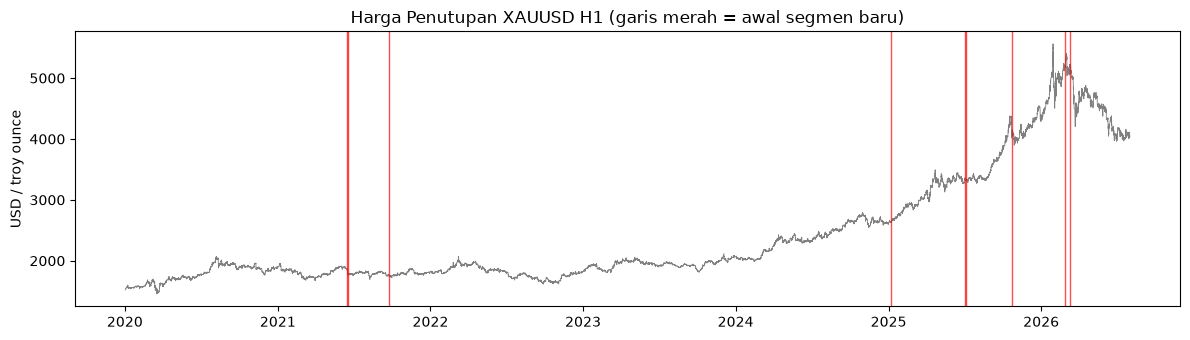

In [9]:
# Visualisasi harga penutupan dan batas segmen baru
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(harga["time"], harga["close"], lw=0.6, color="gray")
for t in tak_jelas["bar_sesudah"]:
    ax.axvline(t, color="red", lw=1, alpha=0.7)

ax.set_title("Harga Penutupan XAUUSD H1 (garis merah = awal segmen baru)")
ax.set_ylabel("USD / troy ounce")
plt.tight_layout()
plt.show()

In [10]:
kolom_simpan = ["time", "open", "high", "low", "close", "setelah_gap", "segment_id"]
harga[kolom_simpan].to_parquet(f"{OUT_DIR}/01_harga.parquet", index=False)
gap.to_csv(f"{OUT_DIR}/01_gap.csv", index=False)
print("Selesai! Tersimpan:", f"{OUT_DIR}/01_harga.parquet", harga[kolom_simpan].shape)

Selesai! Tersimpan: ../data/interim/phase4-p0/01_harga.parquet (38799, 7)
